# 03 - Modelado supervisado del Brent

## Pregunta de investigación

¿La incorporación de riesgo geopolítico e información sobre oferta y demanda mundial permite mejorar la predicción mensual del precio del Brent respecto de utilizar únicamente sus precios históricos?

Se desarrollan regresión y clasificación de punta a punta. La regresión predice el precio del mes siguiente; la clasificación predice si el precio sube. Los tres escenarios A/B/C usan las mismas fechas, un holdout cronológico final y `TimeSeriesSplit` dentro del período de entrenamiento. Además de medir el desempeño, se estudia cómo los modelos usan sus variables mediante coeficientes, importancia por permutación, SHAP y una explicación local con LIME. Estas técnicas describen el comportamiento del modelo: no convierten asociaciones en efectos causales ni compensan un desempeño predictivo débil.

## 1. Diseño y prevención de leakage

- **A - Brent:** nivel actual, rezagos, retornos, promedios móviles y volatilidad.
- **B - Brent + GPR:** agrega GPR con un mes de retraso.
- **C - Brent + GPR + oferta/demanda:** agrega producción, consumo, producción de crudo y balance, también con un mes de retraso.

El retraso de las variables externas es una decisión conservadora frente a los calendarios de publicación. El 20 % final se reserva como test y no se usa para elegir modelos ni hiperparámetros. El escalado se aprende dentro de cada `Pipeline`, por lo que cada fold estima sus propios parámetros sin observar el período de validación.

In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from IPython.display import display
from lime.lime_tabular import LimeTabularExplainer

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (
    GradientBoostingRegressor,
    RandomForestClassifier,
    RandomForestRegressor,
)
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    mean_absolute_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
    root_mean_squared_error,
)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

ROOT = Path.cwd()
if not (ROOT / "data" / "processed").exists():
    ROOT = ROOT.parent
DATA_FILE = ROOT / "data" / "processed" / "brent_gpr_market_monthly.csv"

C:\Users\dra\AppData\Local\Temp\brent-gpr-analysis-20261021\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Carga y feature engineering

**Pregunta metodológica:** ¿cómo representar la memoria del Brent y agregar información externa sin usar datos futuros? Se construye un conjunto deliberadamente pequeño de rezagos, retornos, medias móviles y volatilidad; GPR y STEO ingresan siempre desplazados un mes.

In [2]:
df = pd.read_csv(DATA_FILE, parse_dates=["month"]).sort_values("month").reset_index(drop=True)

# Historia del Brent disponible al cierre de cada mes.
for lag in [1, 2, 3, 6]:
    df[f"brent_lag_{lag}"] = df["brent_price"].shift(lag)
df["brent_return_1m"] = df["brent_price"].pct_change(fill_method=None)
df["brent_return_3m"] = df["brent_price"].pct_change(3, fill_method=None)
df["brent_ma_3"] = df["brent_price"].rolling(3).mean()
df["brent_ma_6"] = df["brent_price"].rolling(6).mean()
df["brent_volatility_6m"] = df["brent_return_1m"].rolling(6).std()

# Variables externas: t-1 para representar disponibilidad de publicación.
df["gpr_lag_1"] = df["GPR"].shift(1)
df["gpr_change_lag_1"] = df["GPR"].diff().shift(1)
df["gpr_log_lag_1"] = np.log1p(df["GPR"]).shift(1)

for source in [
    "world_production", "world_consumption",
    "world_crude_production", "world_market_balance",
]:
    df[f"{source}_lag_1"] = df[source].shift(1)
df["world_market_balance_change_lag_1"] = df["world_market_balance"].diff().shift(1)

features_a = [
    "brent_price", "brent_lag_1", "brent_lag_2", "brent_lag_3", "brent_lag_6",
    "brent_return_1m", "brent_return_3m", "brent_ma_3", "brent_ma_6",
    "brent_volatility_6m",
]
features_b = features_a + ["gpr_lag_1", "gpr_change_lag_1", "gpr_log_lag_1"]
features_c = features_b + [
    "world_production_lag_1", "world_consumption_lag_1",
    "world_crude_production_lag_1", "world_market_balance_lag_1",
    "world_market_balance_change_lag_1",
]
scenarios = {"A - Brent": features_a, "B - Brent + GPR": features_b,
             "C - Brent + GPR + mercado": features_c}

required = features_c + ["brent_price_next_month", "brent_up_next_month"]
model_data = df.dropna(subset=required).copy().reset_index(drop=True)
model_data["brent_up_next_month"] = model_data["brent_up_next_month"].astype(int)

print("Observaciones comparables:", len(model_data))
print("Período comparable:", model_data["month"].min().date(), "a", model_data["month"].max().date())
display(pd.DataFrame({"escenario": scenarios.keys(), "cantidad_variables": [len(v) for v in scenarios.values()]}))

assert not any("next" in feature or "target" in feature for feature in features_c)
assert all(name.endswith("lag_1") for name in features_c if name.startswith(("gpr", "world")))

Observaciones comparables: 329
Período comparable: 1998-07-01 a 2025-11-01


,escenario,cantidad_variables
0,A - Brent,10
1,B - Brent + GPR,13
2,C - Brent + GPR + mercado,18


Los tres escenarios quedan comparables sobre 329 meses, desde julio de 1998 hasta noviembre de 2025. A contiene 10 variables históricas del Brent, B agrega 3 de GPR y C suma 5 del mercado mundial. La siguiente aserción se realiza sobre fechas, no sobre posiciones reindexadas: para cada fila modelada, el valor externo debe coincidir con el mes calendario anterior del dataset original.

In [3]:
lag_check = model_data[["month", "gpr_lag_1", "world_market_balance_lag_1"]].merge(
    df[["month", "GPR", "world_market_balance"]].assign(
        month=lambda x: x["month"] + pd.offsets.MonthBegin(1)
    ),
    on="month",
    how="left",
)
assert np.allclose(lag_check["gpr_lag_1"], lag_check["GPR"])
assert np.allclose(lag_check["world_market_balance_lag_1"], lag_check["world_market_balance"])
print("Control de rezagos externos: correcto")

Control de rezagos externos: correcto


## 3. Separación cronológica y folds temporales

**Pregunta metodológica:** ¿cómo estimar generalización respetando el orden temporal? El entrenamiento crece hacia adelante en cinco folds y el tramo final queda aislado como test.

In [4]:
split_index = int(len(model_data) * 0.80)
train = model_data.iloc[:split_index].copy()
test = model_data.iloc[split_index:].copy()

y_reg_train = train["brent_price_next_month"]
y_reg_test = test["brent_price_next_month"]
y_clf_train = train["brent_up_next_month"]
y_clf_test = test["brent_up_next_month"]

tscv = TimeSeriesSplit(n_splits=5)
fold_rows = []
for fold, (train_idx, valid_idx) in enumerate(tscv.split(train), start=1):
    fold_rows.append({
        "fold": fold,
        "train_inicio": train.iloc[train_idx]["month"].min(),
        "train_fin": train.iloc[train_idx]["month"].max(),
        "valid_inicio": train.iloc[valid_idx]["month"].min(),
        "valid_fin": train.iloc[valid_idx]["month"].max(),
        "n_train": len(train_idx),
        "n_valid": len(valid_idx),
    })
fold_table = pd.DataFrame(fold_rows)

print("Train:", train["month"].min().date(), "a", train["month"].max().date(), f"({len(train)} meses)")
print("Test: ", test["month"].min().date(), "a", test["month"].max().date(), f"({len(test)} meses)")
display(fold_table)

assert train["month"].max() < test["month"].min()
assert all(row.train_fin < row.valid_inicio for row in fold_table.itertuples())

Train: 1998-07-01 a 2020-05-01 (263 meses)
Test:  2020-06-01 a 2025-11-01 (66 meses)


,fold,train_inicio,train_fin,valid_inicio,valid_fin,n_train,n_valid
0,1,1998-07-01,2002-06-01,2002-07-01,2006-01-01,48,43
1,2,1998-07-01,2006-01-01,2006-02-01,2009-08-01,91,43
2,3,1998-07-01,2009-08-01,2009-09-01,2013-03-01,134,43
3,4,1998-07-01,2013-03-01,2013-04-01,2016-10-01,177,43
4,5,1998-07-01,2016-10-01,2016-11-01,2020-05-01,220,43


El entrenamiento abarca julio de 1998–mayo de 2020 (263 meses) y el test junio de 2020–noviembre de 2025 (66 meses). Todos los folds terminan antes de que comience su validación y el test ocurre después del último dato de entrenamiento; esto evita la mezcla aleatoria de regímenes y reduce el riesgo de leakage temporal.

## 4. Modelos y baselines

Se comparan modelos lineales regularizados, ensambles de árboles y referencias simples. La persistencia pregunta si vale la pena modelar en lugar de repetir el último precio; la clase mayoritaria fija balanced accuracy en 0,50 y evita confundir un F1 alto por desbalance con capacidad real para distinguir subas y no subas.

In [5]:
regression_models = {
    "Ridge": Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=1.0))]),
    "Random Forest": Pipeline([("model", RandomForestRegressor(
        n_estimators=200, max_depth=6, min_samples_leaf=3,
        random_state=RANDOM_STATE, n_jobs=1,
    ))]),
    "Gradient Boosting": Pipeline([("model", GradientBoostingRegressor(
        n_estimators=120, max_depth=2, learning_rate=0.04,
        random_state=RANDOM_STATE,
    ))]),
}

classification_models = {
    "Regresión logística": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ]),
    "Random Forest": Pipeline([("model", RandomForestClassifier(
        n_estimators=200, max_depth=5, min_samples_leaf=3,
        class_weight="balanced", random_state=RANDOM_STATE, n_jobs=1,
    ))]),
}

print("Baseline regresión: persistencia (precio siguiente = precio actual).")
print("Baseline clasificación: clase mayoritaria aprendida solo en train.")

Baseline regresión: persistencia (precio siguiente = precio actual).
Baseline clasificación: clase mayoritaria aprendida solo en train.


## 5. Validación temporal de modelos base

En regresión, **MAE** es el error absoluto medio en USD/barril, **RMSE** penaliza más los errores grandes y **R²** compara con predecir la media, no con la persistencia. En clasificación, accuracy mide aciertos totales; balanced accuracy promedia el acierto de ambas clases; precision, recall y F1 describen la clase «sube»; ROC-AUC evalúa el ordenamiento probabilístico a través de todos los umbrales.

In [6]:
regression_cv_rows = []
for scenario, features in scenarios.items():
    X = train[features]
    for model_name, model in regression_models.items():
        scores = cross_validate(
            model, X, y_reg_train, cv=tscv,
            scoring={"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error", "r2": "r2"},
            return_train_score=True, n_jobs=1,
        )
        regression_cv_rows.append({
            "escenario": scenario, "modelo": model_name,
            "RMSE_validación": -scores["test_rmse"].mean(),
            "RMSE_std": scores["test_rmse"].std(),
            "MAE_validación": -scores["test_mae"].mean(),
            "R2_validación": scores["test_r2"].mean(),
            "RMSE_train": -scores["train_rmse"].mean(),
            "brecha_RMSE": -scores["test_rmse"].mean() + scores["train_rmse"].mean(),
        })
regression_cv = pd.DataFrame(regression_cv_rows).sort_values(["escenario", "RMSE_validación"])
display(regression_cv.round(3))

,escenario,modelo,RMSE_validación,RMSE_std,MAE_validación,R2_validación,RMSE_train,brecha_RMSE
0,A - Brent,Ridge,7.347,3.256,5.382,0.811,4.027,3.320
2,A - Brent,Gradient Boosting,13.203,7.871,9.515,0.232,2.332,10.871
1,A - Brent,Random Forest,13.354,7.641,9.800,0.225,2.791,10.563
3,B - Brent + GPR,Ridge,7.360,3.373,5.405,0.810,3.971,3.389
4,B - Brent + GPR,Random Forest,13.265,7.676,9.592,0.226,2.704,10.561
5,B - Brent + GPR,Gradient Boosting,13.618,7.719,9.863,0.174,2.298,11.320
6,C - Brent + GPR + mercado,Ridge,9.325,2.981,7.143,0.733,3.804,5.521
8,C - Brent + GPR + mercado,Gradient Boosting,13.484,7.606,9.798,0.206,2.251,11.233
7,C - Brent + GPR + mercado,Random Forest,13.496,7.789,9.833,0.212,2.631,10.864


In [7]:
classification_cv_rows = []
classification_scoring = {
    "accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy",
    "precision": "precision", "recall": "recall", "f1": "f1",
    "f1_macro": "f1_macro", "roc_auc": "roc_auc",
}
for scenario, features in scenarios.items():
    X = train[features]
    for model_name, model in classification_models.items():
        scores = cross_validate(
            model, X, y_clf_train, cv=tscv, scoring=classification_scoring,
            return_train_score=True, n_jobs=1,
        )
        classification_cv_rows.append({
            "escenario": scenario, "modelo": model_name,
            "Balanced_accuracy_validación": scores["test_balanced_accuracy"].mean(),
            "Balanced_accuracy_std": scores["test_balanced_accuracy"].std(),
            "Accuracy_validación": scores["test_accuracy"].mean(),
            "Precision_validación": scores["test_precision"].mean(),
            "Recall_validación": scores["test_recall"].mean(),
            "F1_positivo_validación": scores["test_f1"].mean(),
            "F1_macro_validación": scores["test_f1_macro"].mean(),
            "ROC_AUC_validación": scores["test_roc_auc"].mean(),
            "Balanced_accuracy_train": scores["train_balanced_accuracy"].mean(),
            "brecha_balanced_accuracy": scores["train_balanced_accuracy"].mean() - scores["test_balanced_accuracy"].mean(),
        })
classification_cv = pd.DataFrame(classification_cv_rows).sort_values(
    ["escenario", "Balanced_accuracy_validación"], ascending=[True, False]
)
display(classification_cv.round(3))


,escenario,modelo,Balanced_accuracy_validación,Balanced_accuracy_std,Accuracy_validación,Precision_validación,Recall_validación,F1_positivo_validación,F1_macro_validación,ROC_AUC_validación,Balanced_accuracy_train,brecha_balanced_accuracy
1,A - Brent,Random Forest,0.496,0.066,0.474,0.568,0.452,0.429,0.412,0.508,0.919,0.423
0,A - Brent,Regresión logística,0.472,0.037,0.484,0.540,0.591,0.508,0.384,0.497,0.577,0.105
3,B - Brent + GPR,Random Forest,0.523,0.063,0.507,0.585,0.498,0.459,0.448,0.552,0.938,0.415
2,B - Brent + GPR,Regresión logística,0.494,0.078,0.502,0.531,0.584,0.531,0.453,0.509,0.649,0.154
5,C - Brent + GPR + mercado,Random Forest,0.493,0.025,0.479,0.462,0.491,0.426,0.388,0.550,0.964,0.472
4,C - Brent + GPR + mercado,Regresión logística,0.481,0.057,0.470,0.584,0.491,0.423,0.383,0.517,0.667,0.186


Ridge es el mejor regresor base en los tres escenarios: RMSE de validación 7,347 en A, 7,360 en B y 9,325 en C. Agregar GPR prácticamente no cambia el error, mientras C lo empeora; además, el desvío de 2,98–3,37 entre folds revela sensibilidad al período. Random Forest y Gradient Boosting bajan su RMSE de entrenamiento a cerca de 2–3, pero validan alrededor de 13,2–13,5, con brechas superiores a 10: evidencia clara de overfitting.

En clasificación, los resultados de validación permanecen cerca de 0,50 de balanced accuracy. Random Forest B alcanza 0,523, pero su desvío es 0,063 y su valor de entrenamiento 0,938; esa diferencia decimal no es una mejora estable. Las brechas de los bosques (0,415–0,472) son mucho mayores que las de la regresión logística, aunque esta tampoco supera de forma consistente el nivel neutral.

## 6. Baselines con los mismos folds

**Pregunta de control:** ¿los modelos aprenden más que reglas triviales evaluadas en exactamente los mismos períodos? Los baselines se recalculan dentro de cada fold para evitar comparaciones con ventanas diferentes.

In [8]:
baseline_reg_folds = []
baseline_clf_folds = []
for fold, (train_idx, valid_idx) in enumerate(tscv.split(train), start=1):
    y_reg_valid = y_reg_train.iloc[valid_idx]
    persistence = train.iloc[valid_idx]["brent_price"]
    baseline_reg_folds.append({
        "fold": fold,
        "MAE": mean_absolute_error(y_reg_valid, persistence),
        "RMSE": root_mean_squared_error(y_reg_valid, persistence),
        "R2": r2_score(y_reg_valid, persistence),
    })

    dummy = DummyClassifier(strategy="most_frequent")
    X_dummy_train = np.zeros((len(train_idx), 1))
    X_dummy_valid = np.zeros((len(valid_idx), 1))
    y_fold_train = y_clf_train.iloc[train_idx]
    y_fold_valid = y_clf_train.iloc[valid_idx]
    dummy.fit(X_dummy_train, y_fold_train)
    pred = dummy.predict(X_dummy_valid)
    proba_matrix = dummy.predict_proba(X_dummy_valid)
    proba = proba_matrix[:, list(dummy.classes_).index(1)] if 1 in dummy.classes_ else np.zeros(len(valid_idx))
    baseline_clf_folds.append({
        "fold": fold,
        "Accuracy": accuracy_score(y_fold_valid, pred),
        "Balanced_accuracy": balanced_accuracy_score(y_fold_valid, pred),
        "Precision": precision_score(y_fold_valid, pred, zero_division=0),
        "Recall": recall_score(y_fold_valid, pred, zero_division=0),
        "F1_positivo": f1_score(y_fold_valid, pred, zero_division=0),
        "F1_macro": f1_score(y_fold_valid, pred, average="macro", zero_division=0),
        "ROC_AUC": roc_auc_score(y_fold_valid, proba) if y_fold_valid.nunique() == 2 else np.nan,
    })

baseline_reg_cv = pd.DataFrame(baseline_reg_folds)
baseline_clf_cv = pd.DataFrame(baseline_clf_folds)
print("Persistencia - promedio por folds:")
display(baseline_reg_cv.mean(numeric_only=True).to_frame("promedio").T.round(3))
print("Clase mayoritaria - promedio por folds:")
display(baseline_clf_cv.mean(numeric_only=True).to_frame("promedio").T.round(3))


Persistencia - promedio por folds:


,fold,MAE,RMSE,R2
promedio,3.0,4.617,6.017,0.87


Clase mayoritaria - promedio por folds:


,fold,Accuracy,Balanced_accuracy,Precision,Recall,F1_positivo,F1_macro,ROC_AUC
promedio,3.0,0.591,0.5,0.591,1.0,0.742,0.371,0.5


La persistencia obtiene RMSE medio 6,017 y MAE 4,617, mejores que todos los modelos de regresión base en validación temporal. En clasificación, la mayoría alcanza balanced accuracy 0,500; su accuracy 0,591 y F1 0,742 provienen de predecir siempre «sube» (recall 1,0), no de separar las clases. Por eso RMSE y balanced accuracy son los criterios centrales de comparación.

## 7. Optimización compacta y temporal

In [9]:
regression_searches = {}
regression_tuning_rows = []
reg_grid = {
    "model__n_estimators": [150],
    "model__max_depth": [4, 8, None],
    "model__min_samples_leaf": [2, 5],
}

for scenario, features in scenarios.items():
    search = GridSearchCV(
        Pipeline([("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1))]),
        param_grid=reg_grid, cv=tscv, scoring="neg_root_mean_squared_error", n_jobs=1,
    )
    search.fit(train[features], y_reg_train)
    regression_searches[scenario] = search
    base_rmse = regression_cv.query("escenario == @scenario and modelo == 'Random Forest'")["RMSE_validación"].iloc[0]
    regression_tuning_rows.append({
        "escenario": scenario, "RMSE_RF_base": base_rmse,
        "RMSE_RF_optimizado": -search.best_score_, "mejores_parámetros": search.best_params_,
    })
regression_tuning = pd.DataFrame(regression_tuning_rows)
display(regression_tuning)

,escenario,RMSE_RF_base,RMSE_RF_optimizado,mejores_parámetros
0,A - Brent,13.353890,13.436576,"{'model__max_depth': 4, 'model__min_samples_le..."
1,B - Brent + GPR,13.265358,13.404723,"{'model__max_depth': 8, 'model__min_samples_le..."
2,C - Brent + GPR + mercado,13.495745,13.559834,"{'model__max_depth': 4, 'model__min_samples_le..."


In [10]:
classification_searches = {}
classification_tuning_rows = []
clf_grid = {
    "model__n_estimators": [150],
    "model__max_depth": [3, 6, None],
    "model__min_samples_leaf": [2, 5],
}

for scenario, features in scenarios.items():
    search = GridSearchCV(
        Pipeline([("model", RandomForestClassifier(
            class_weight="balanced", random_state=RANDOM_STATE, n_jobs=1,
        ))]),
        param_grid=clf_grid, cv=tscv, scoring="balanced_accuracy", n_jobs=1,
    )
    search.fit(train[features], y_clf_train)
    classification_searches[scenario] = search
    base_score = classification_cv.query(
        "escenario == @scenario and modelo == 'Random Forest'"
    )["Balanced_accuracy_validación"].iloc[0]
    classification_tuning_rows.append({
        "escenario": scenario, "Balanced_accuracy_RF_base": base_score,
        "Balanced_accuracy_RF_optimizado": search.best_score_,
        "mejores_parámetros": search.best_params_,
    })
classification_tuning = pd.DataFrame(classification_tuning_rows)
display(classification_tuning)

,escenario,Balanced_accuracy_RF_base,Balanced_accuracy_RF_optimizado,mejores_parámetros
0,A - Brent,0.495626,0.502816,"{'model__max_depth': 3, 'model__min_samples_le..."
1,B - Brent + GPR,0.522820,0.531897,"{'model__max_depth': 6, 'model__min_samples_le..."
2,C - Brent + GPR + mercado,0.492711,0.520233,"{'model__max_depth': 3, 'model__min_samples_le..."


La búsqueda ajusta solo profundidad, cantidad de árboles y mínimo de observaciones por hoja, siempre con `TimeSeriesSplit`. En regresión, el Random Forest optimizado no mejora su versión base: el RMSE sube levemente en A/B/C y permanece alrededor de 13,4–13,6. En clasificación aparecen mejoras pequeñas de validación —B llega a 0,532 y C a 0,520—, pero siguen próximas a 0,50 y deben contrastarse con el test antes de atribuirles valor. La optimización reduce la flexibilidad de algunos árboles, pero no elimina la inestabilidad temporal.

## 8. Selección previa al test

La regla de selección se fija antes de consultar el test: menor **RMSE medio de validación temporal** para regresión y mayor **balanced accuracy media** para clasificación. Los hiperparámetros y la comparación A/B/C usan exclusivamente los cinco folds del conjunto de entrenamiento. El baseline se informa por separado porque no es un escenario adicional ni un modelo aprendido.


In [11]:
regression_selection_rows = []
for row in regression_cv.itertuples(index=False):
    regression_selection_rows.append({
        "escenario": row.escenario,
        "modelo": row.modelo,
        "RMSE_CV": row.RMSE_validación,
        "MAE_CV": row.MAE_validación,
        "R2_CV": row.R2_validación,
        "origen": "configuración base",
    })
for scenario, search in regression_searches.items():
    regression_selection_rows.append({
        "escenario": scenario,
        "modelo": "Random Forest optimizado",
        "RMSE_CV": -search.best_score_,
        "MAE_CV": np.nan,
        "R2_CV": np.nan,
        "origen": "GridSearchCV",
    })
regression_validation_ranking = pd.DataFrame(regression_selection_rows).sort_values("RMSE_CV").reset_index(drop=True)
final_reg_config = regression_validation_ranking.iloc[0]

classification_selection_rows = []
for row in classification_cv.itertuples(index=False):
    classification_selection_rows.append({
        "escenario": row.escenario,
        "modelo": row.modelo,
        "Balanced_accuracy_CV": row.Balanced_accuracy_validación,
        "Accuracy_CV": row.Accuracy_validación,
        "F1_macro_CV": row.F1_macro_validación,
        "ROC_AUC_CV": row.ROC_AUC_validación,
        "origen": "configuración base",
    })
for scenario, search in classification_searches.items():
    classification_selection_rows.append({
        "escenario": scenario,
        "modelo": "Random Forest optimizado",
        "Balanced_accuracy_CV": search.best_score_,
        "Accuracy_CV": np.nan,
        "F1_macro_CV": np.nan,
        "ROC_AUC_CV": np.nan,
        "origen": "GridSearchCV",
    })
classification_validation_ranking = pd.DataFrame(classification_selection_rows).sort_values(
    "Balanced_accuracy_CV", ascending=False
).reset_index(drop=True)
final_clf_config = classification_validation_ranking.iloc[0]

selection_summary_cv = pd.DataFrame([
    {
        "tarea": "Regresión",
        "métrica_principal": "RMSE CV (menor es mejor)",
        "escenario_seleccionado": final_reg_config["escenario"],
        "modelo_seleccionado": final_reg_config["modelo"],
        "valor_CV": final_reg_config["RMSE_CV"],
        "mejor_baseline_CV": baseline_reg_cv["RMSE"].mean(),
    },
    {
        "tarea": "Clasificación",
        "métrica_principal": "Balanced accuracy CV (mayor es mejor)",
        "escenario_seleccionado": final_clf_config["escenario"],
        "modelo_seleccionado": final_clf_config["modelo"],
        "valor_CV": final_clf_config["Balanced_accuracy_CV"],
        "mejor_baseline_CV": baseline_clf_cv["Balanced_accuracy"].mean(),
    },
])
display(selection_summary_cv.round(3))
print("La configuración final queda congelada antes de evaluar el test.")


,tarea,métrica_principal,escenario_seleccionado,modelo_seleccionado,valor_CV,mejor_baseline_CV
0,Regresión,RMSE CV (menor es mejor),A - Brent,Ridge,7.347,6.017
1,Clasificación,Balanced accuracy CV (mayor es mejor),B - Brent + GPR,Random Forest optimizado,0.532,0.500


La configuración final queda congelada antes de evaluar el test.


## 9. Evaluación histórica en test (solo reporte)

El test mensual ya fue inspeccionado durante el desarrollo, por lo que no puede presentarse como una evaluación independiente completamente intacta. Se conserva como **evaluación histórica exploratoria** de configuraciones elegidas con validación; ninguna fila se ordena ni se selecciona por sus resultados de test. MAE y RMSE se expresan en USD por barril; R² compara contra predecir la media y no representa un porcentaje de aciertos.


In [12]:
selected_regression_models = {}
regression_test_rows = []
for scenario, features in scenarios.items():
    base_rows = regression_cv.query("escenario == @scenario")
    candidates = dict(zip(base_rows["modelo"], base_rows["RMSE_validación"]))
    candidates["Random Forest optimizado"] = -regression_searches[scenario].best_score_
    selected_name = min(candidates, key=candidates.get)
    if selected_name == "Random Forest optimizado":
        fitted = regression_searches[scenario].best_estimator_
    else:
        fitted = clone(regression_models[selected_name]).fit(train[features], y_reg_train)
    selected_regression_models[scenario] = fitted
    train_pred = fitted.predict(train[features])
    test_pred = fitted.predict(test[features])
    regression_test_rows.append({
        "escenario": scenario,
        "modelo_seleccionado_por_CV": selected_name,
        "RMSE_CV_selección": candidates[selected_name],
        "MAE_test": mean_absolute_error(y_reg_test, test_pred),
        "RMSE_test": root_mean_squared_error(y_reg_test, test_pred),
        "R2_test": r2_score(y_reg_test, test_pred),
        "RMSE_train": root_mean_squared_error(y_reg_train, train_pred),
    })

regression_test = pd.DataFrame(regression_test_rows)
persistence_test = test["brent_price"]
regression_baseline_test = {
    "MAE_test": mean_absolute_error(y_reg_test, persistence_test),
    "RMSE_test": root_mean_squared_error(y_reg_test, persistence_test),
    "R2_test": r2_score(y_reg_test, persistence_test),
}
print("Configuraciones seleccionadas por validación; test solo para reporte histórico:")
display(regression_test.round(3))
print("Baseline de persistencia en test:", {k: round(v, 3) for k, v in regression_baseline_test.items()})


Configuraciones seleccionadas por validación; test solo para reporte histórico:


,escenario,modelo_seleccionado_por_CV,RMSE_CV_selección,MAE_test,RMSE_test,R2_test,RMSE_train
0,A - Brent,Ridge,7.347,5.014,6.238,0.864,5.383
1,B - Brent + GPR,Ridge,7.360,4.962,6.254,0.863,5.362
2,C - Brent + GPR + mercado,Ridge,9.325,5.032,6.290,0.861,5.310


Baseline de persistencia en test: {'MAE_test': 4.942, 'RMSE_test': 6.243, 'R2_test': 0.863}


**Interpretación de regresión.** Ridge es seleccionado en A, B y C. El escenario A obtiene el menor RMSE (6,238) y R² 0,864, pero la persistencia alcanza RMSE 6,243: la ventaja es apenas 0,006 USD/barril, muy inferior a la variación entre folds. Además, A tiene MAE 5,014 frente a 4,942 de persistencia; B reduce ligeramente el MAE a 4,962 pero empeora RMSE, y C es el peor de los tres. En consecuencia, ningún escenario supera al baseline de manera consistente entre métricas.

In [13]:
selected_classification_models = {}
classification_test_rows = []
for scenario, features in scenarios.items():
    base_rows = classification_cv.query("escenario == @scenario")
    candidates = dict(zip(base_rows["modelo"], base_rows["Balanced_accuracy_validación"]))
    candidates["Random Forest optimizado"] = classification_searches[scenario].best_score_
    selected_name = max(candidates, key=candidates.get)
    if selected_name == "Random Forest optimizado":
        fitted = classification_searches[scenario].best_estimator_
    else:
        fitted = clone(classification_models[selected_name]).fit(train[features], y_clf_train)
    selected_classification_models[scenario] = fitted
    train_pred = fitted.predict(train[features])
    test_pred = fitted.predict(test[features])
    test_proba = fitted.predict_proba(test[features])[:, 1]
    classification_test_rows.append({
        "escenario": scenario,
        "modelo_seleccionado_por_CV": selected_name,
        "Balanced_accuracy_CV_selección": candidates[selected_name],
        "Accuracy_test": accuracy_score(y_clf_test, test_pred),
        "Accuracy_test_pct": 100 * accuracy_score(y_clf_test, test_pred),
        "Balanced_accuracy_test": balanced_accuracy_score(y_clf_test, test_pred),
        "Balanced_accuracy_test_pct": 100 * balanced_accuracy_score(y_clf_test, test_pred),
        "Precision_test": precision_score(y_clf_test, test_pred, zero_division=0),
        "Recall_test": recall_score(y_clf_test, test_pred, zero_division=0),
        "F1_positivo_test": f1_score(y_clf_test, test_pred, zero_division=0),
        "F1_macro_test": f1_score(y_clf_test, test_pred, average="macro", zero_division=0),
        "ROC_AUC_test": roc_auc_score(y_clf_test, test_proba),
        "Balanced_accuracy_train": balanced_accuracy_score(y_clf_train, train_pred),
    })

classification_test = pd.DataFrame(classification_test_rows)
dummy = DummyClassifier(strategy="most_frequent").fit(np.zeros((len(y_clf_train), 1)), y_clf_train)
dummy_X_test = np.zeros((len(y_clf_test), 1))
dummy_pred = dummy.predict(dummy_X_test)
dummy_proba_matrix = dummy.predict_proba(dummy_X_test)
dummy_proba = dummy_proba_matrix[:, list(dummy.classes_).index(1)] if 1 in dummy.classes_ else np.zeros(len(y_clf_test))
classification_baseline_test = {
    "Accuracy_test": accuracy_score(y_clf_test, dummy_pred),
    "Accuracy_test_pct": 100 * accuracy_score(y_clf_test, dummy_pred),
    "Balanced_accuracy_test": balanced_accuracy_score(y_clf_test, dummy_pred),
    "Balanced_accuracy_test_pct": 100 * balanced_accuracy_score(y_clf_test, dummy_pred),
    "Precision_test": precision_score(y_clf_test, dummy_pred, zero_division=0),
    "Recall_test": recall_score(y_clf_test, dummy_pred, zero_division=0),
    "F1_positivo_test": f1_score(y_clf_test, dummy_pred, zero_division=0),
    "F1_macro_test": f1_score(y_clf_test, dummy_pred, average="macro", zero_division=0),
    "ROC_AUC_test": roc_auc_score(y_clf_test, dummy_proba),
}
display(classification_test.round(3))
print("Baseline mayoritario en test:", {k: round(v, 3) for k, v in classification_baseline_test.items()})


,escenario,modelo_seleccionado_por_CV,Balanced_accuracy_CV_selección,Accuracy_test,Accuracy_test_pct,Balanced_accuracy_test,Balanced_accuracy_test_pct,Precision_test,Recall_test,F1_positivo_test,F1_macro_test,ROC_AUC_test,Balanced_accuracy_train
0,A - Brent,Random Forest optimizado,0.503,0.470,46.970,0.465,46.507,0.488,0.618,0.545,0.455,0.494,0.775
1,B - Brent + GPR,Random Forest optimizado,0.532,0.455,45.455,0.456,45.588,0.467,0.412,0.438,0.454,0.518,0.942
2,C - Brent + GPR + mercado,Random Forest optimizado,0.520,0.485,48.485,0.491,49.081,0.500,0.294,0.370,0.467,0.555,0.796


Baseline mayoritario en test: {'Accuracy_test': 0.515, 'Accuracy_test_pct': 51.515, 'Balanced_accuracy_test': 0.5, 'Balanced_accuracy_test_pct': 50.0, 'Precision_test': 0.515, 'Recall_test': 1.0, 'F1_positivo_test': 0.68, 'F1_macro_test': 0.34, 'ROC_AUC_test': 0.5}


**Interpretación de clasificación.** La tabla no decide el ganador: documenta cómo se comporta en el test histórico la configuración que cada escenario eligió por CV. La selección global previa corresponde al Random Forest optimizado de B (balanced accuracy CV 0,532); en test obtiene 0,456, por debajo del 0,500 de la mayoría. C alcanza ROC-AUC 0,555 en este período, pero no puede reemplazar retroactivamente a B por ese resultado. El F1 positivo alto del baseline surge de predecir siempre «sube»; F1 macro y balanced accuracy exhiben mejor su incapacidad para distinguir ambas clases.


## 10. Comparación del mismo algoritmo entre escenarios

Esta comparación mantiene fijo el Random Forest optimizado para aislar el efecto de agregar bloques de variables. Se distingue de comparar el mejor modelo de cada escenario, porque un cambio de algoritmo podría confundirse con el aporte de GPR o del mercado.

,escenario,RMSE_RF_optimizado_test,MAE_RF_optimizado_test
0,A - Brent,6.485,5.056
1,B - Brent + GPR,6.353,4.950
2,C - Brent + GPR + mercado,6.376,5.027


,escenario,Balanced_accuracy_RF_optimizado_test,F1_RF_optimizado_test,ROC_AUC_RF_optimizado_test
0,A - Brent,0.465,0.545,0.494
1,B - Brent + GPR,0.456,0.438,0.518
2,C - Brent + GPR + mercado,0.491,0.370,0.555


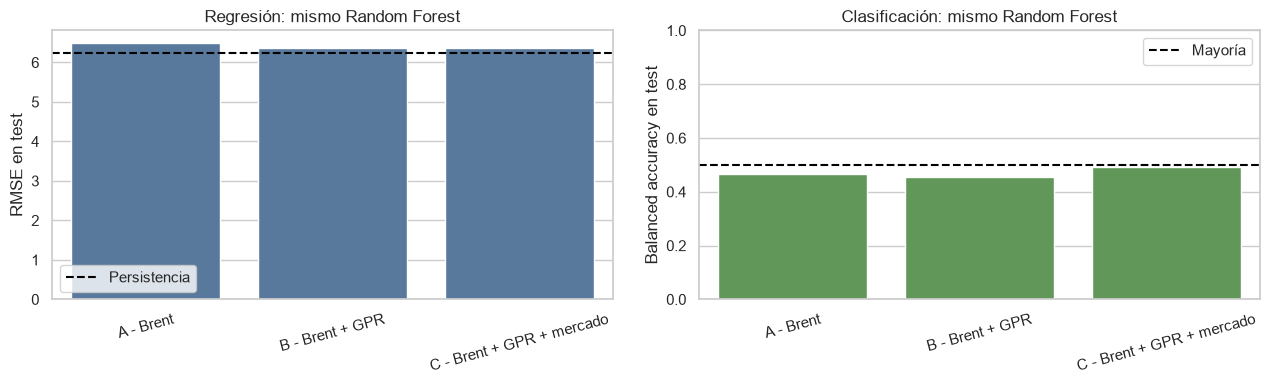

In [14]:
same_algorithm_reg_rows = []
same_algorithm_clf_rows = []
for scenario, features in scenarios.items():
    reg_model = regression_searches[scenario].best_estimator_
    reg_pred = reg_model.predict(test[features])
    same_algorithm_reg_rows.append({
        "escenario": scenario,
        "RMSE_RF_optimizado_test": root_mean_squared_error(y_reg_test, reg_pred),
        "MAE_RF_optimizado_test": mean_absolute_error(y_reg_test, reg_pred),
    })

    clf_model = classification_searches[scenario].best_estimator_
    clf_pred = clf_model.predict(test[features])
    clf_proba = clf_model.predict_proba(test[features])[:, 1]
    same_algorithm_clf_rows.append({
        "escenario": scenario,
        "Balanced_accuracy_RF_optimizado_test": balanced_accuracy_score(y_clf_test, clf_pred),
        "F1_RF_optimizado_test": f1_score(y_clf_test, clf_pred, zero_division=0),
        "ROC_AUC_RF_optimizado_test": roc_auc_score(y_clf_test, clf_proba),
    })

same_algorithm_reg = pd.DataFrame(same_algorithm_reg_rows)
same_algorithm_clf = pd.DataFrame(same_algorithm_clf_rows)
display(same_algorithm_reg.round(3))
display(same_algorithm_clf.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(data=same_algorithm_reg, x="escenario", y="RMSE_RF_optimizado_test", color="#4c78a8", ax=axes[0])
axes[0].axhline(regression_baseline_test["RMSE_test"], color="black", linestyle="--", label="Persistencia")
axes[0].set(title="Regresión: mismo Random Forest", xlabel="", ylabel="RMSE en test")
axes[0].tick_params(axis="x", rotation=15)
axes[0].legend()
sns.barplot(data=same_algorithm_clf, x="escenario", y="Balanced_accuracy_RF_optimizado_test", color="#59a14f", ax=axes[1])
axes[1].axhline(classification_baseline_test["Balanced_accuracy_test"], color="black", linestyle="--", label="Mayoría")
axes[1].set(title="Clasificación: mismo Random Forest", xlabel="", ylabel="Balanced accuracy en test", ylim=(0, 1))
axes[1].tick_params(axis="x", rotation=15)
axes[1].legend()
plt.tight_layout()
plt.show()

Con el mismo Random Forest de regresión, B reduce el RMSE de A de 6,485 a 6,353 y C queda en 6,376; ninguno supera el RMSE 6,243 de persistencia. En clasificación, C logra el mayor ROC-AUC (0,555), pero su balanced accuracy es 0,491 y su F1 0,370. Las diferencias A/B/C son pequeñas, cambian según la métrica y no sostienen una mejora robusta de las variables externas.

## 11. Diagnóstico de los mejores modelos

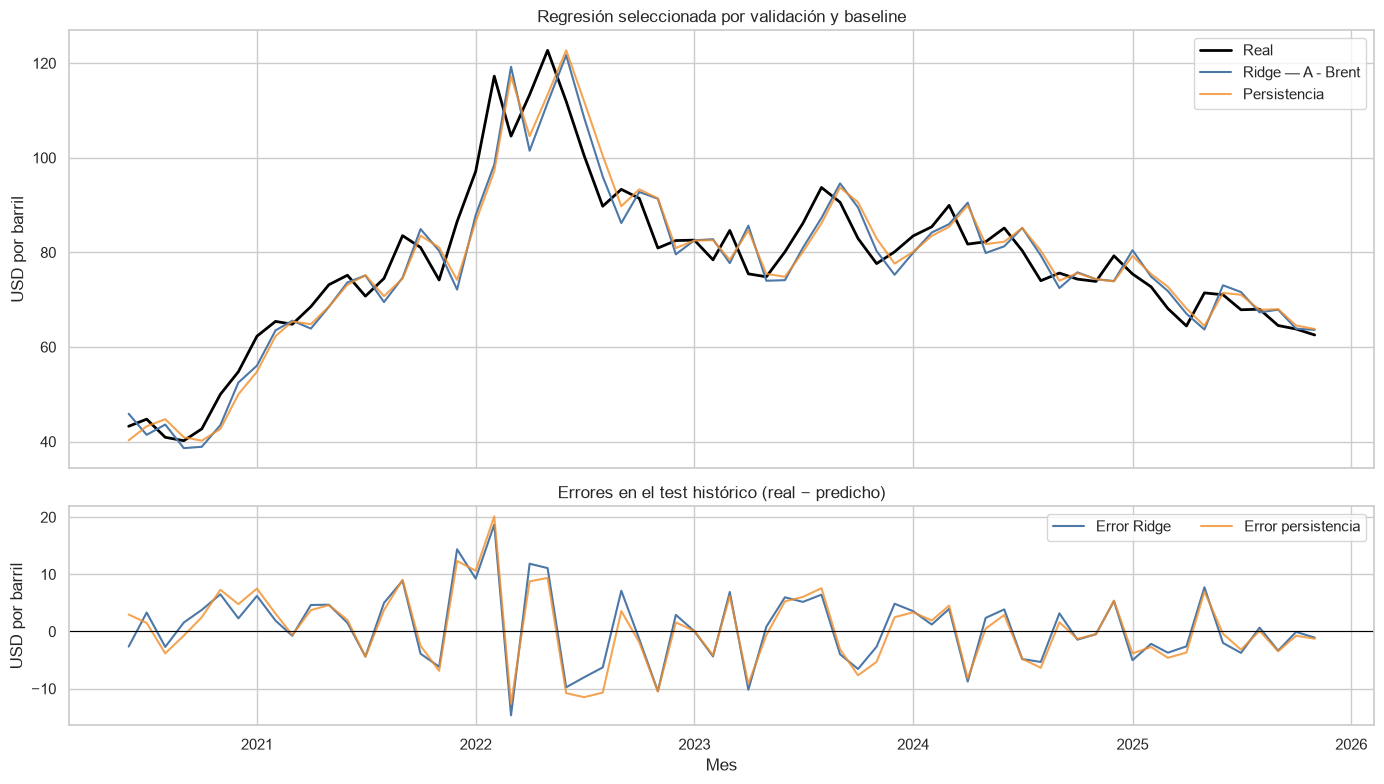

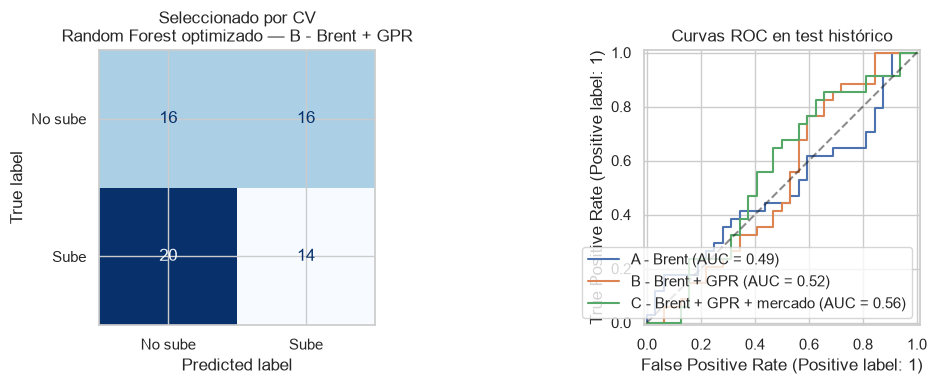

In [15]:
best_reg_scenario = final_reg_config["escenario"]
best_reg_model_name = final_reg_config["modelo"]
best_reg_model = selected_regression_models[best_reg_scenario]
best_reg_features = scenarios[best_reg_scenario]
best_reg_pred = best_reg_model.predict(test[best_reg_features])

best_reg_error = y_reg_test.to_numpy() - best_reg_pred
persistence_error = y_reg_test.to_numpy() - persistence_test.to_numpy()
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
axes[0].plot(test["month"], y_reg_test, label="Real", color="black", linewidth=2)
axes[0].plot(test["month"], best_reg_pred, label=f"{best_reg_model_name} — {best_reg_scenario}", color="#4c78a8")
axes[0].plot(test["month"], persistence_test, label="Persistencia", color="#f28e2b", alpha=0.8)
axes[0].set(title="Regresión seleccionada por validación y baseline", ylabel="USD por barril")
axes[0].legend()
axes[1].plot(test["month"], best_reg_error, label=f"Error {best_reg_model_name}", color="#4c78a8")
axes[1].plot(test["month"], persistence_error, label="Error persistencia", color="#f28e2b", alpha=0.8)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set(title="Errores en el test histórico (real − predicho)", xlabel="Mes", ylabel="USD por barril")
axes[1].legend(ncol=2)
plt.tight_layout()
plt.show()

best_clf_scenario = final_clf_config["escenario"]
best_clf_model_name = final_clf_config["modelo"]
best_clf_model = selected_classification_models[best_clf_scenario]
best_clf_features = scenarios[best_clf_scenario]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay.from_estimator(
    best_clf_model, test[best_clf_features], y_clf_test,
    display_labels=["No sube", "Sube"], cmap="Blues", ax=axes[0], colorbar=False,
)
axes[0].set_title(f"Seleccionado por CV\n{best_clf_model_name} — {best_clf_scenario}")
for scenario, features in scenarios.items():
    model = selected_classification_models[scenario]
    RocCurveDisplay.from_estimator(model, test[features], y_clf_test, name=scenario, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[1].set_title("Curvas ROC en test histórico")
plt.tight_layout()
plt.show()


Ridge A fue seleccionado por validación, no por la pequeña ventaja de RMSE observada en test. Su trayectoria sigue el nivel general del Brent, pero no mejora de manera consistente a persistencia: el RMSE difiere apenas USD 0,006 y el MAE favorece al baseline. Los residuos se concentran en meses de cambios bruscos. La matriz corresponde al clasificador B elegido por CV; su deterioro hasta balanced accuracy 0,456 en el test histórico confirma que la separación de subas y no subas no es estable.


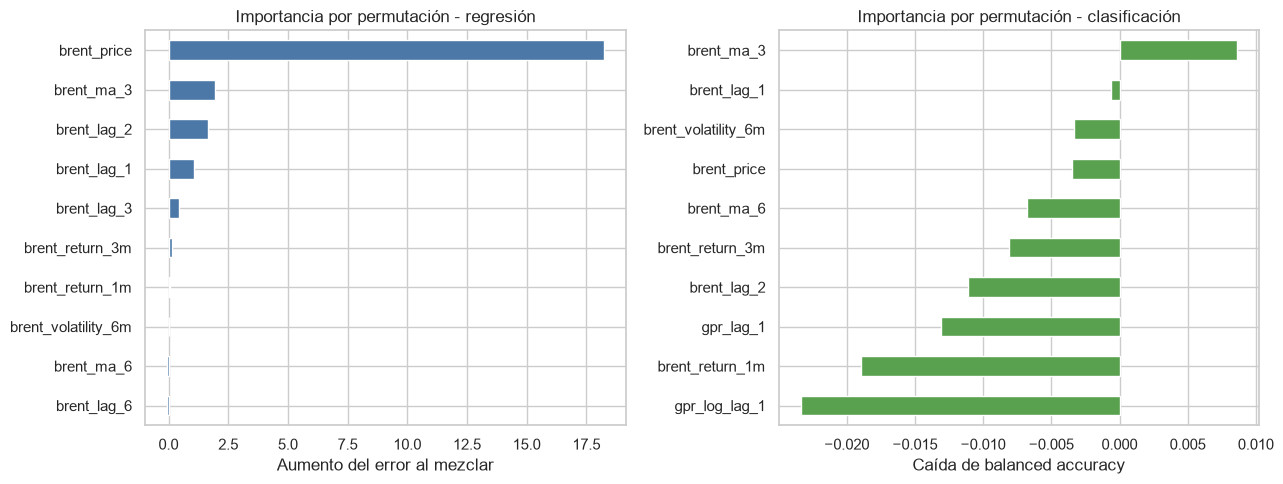

In [16]:
reg_importance = permutation_importance(
    best_reg_model, test[best_reg_features], y_reg_test,
    scoring="neg_root_mean_squared_error", n_repeats=20,
    random_state=RANDOM_STATE, n_jobs=1,
)
clf_importance = permutation_importance(
    best_clf_model, test[best_clf_features], y_clf_test,
    scoring="balanced_accuracy", n_repeats=20,
    random_state=RANDOM_STATE, n_jobs=1,
)

reg_imp = pd.Series(reg_importance.importances_mean, index=best_reg_features).sort_values().tail(10)
clf_imp = pd.Series(clf_importance.importances_mean, index=best_clf_features).sort_values().tail(10)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
reg_imp.plot(kind="barh", color="#4c78a8", ax=axes[0])
axes[0].set(title="Importancia por permutación - regresión", xlabel="Aumento del error al mezclar")
clf_imp.plot(kind="barh", color="#59a14f", ax=axes[1])
axes[1].set(title="Importancia por permutación - clasificación", xlabel="Caída de balanced accuracy")
plt.tight_layout()
plt.show()

En Ridge A, permutar el precio actual aumenta el RMSE cerca de USD 18, mientras la media móvil de tres meses y los rezagos aportan mucho menos: la predicción depende principalmente de la persistencia del nivel. En el clasificador B seleccionado por CV, las variaciones de balanced accuracy son pequeñas e inestables. Una variable puede ser importante para el mecanismo de un modelo que, aun así, no supera el baseline; estas barras explican el modelo y no validan por sí mismas su utilidad predictiva.


## 12. Coeficientes del modelo Ridge

**Pregunta de interpretabilidad:** ¿qué variables utiliza y en qué dirección el mejor modelo de regresión seleccionado? Ridge A incluye `StandardScaler`: cada coeficiente expresa el cambio estimado en el Brent del mes siguiente, en USD/barril, asociado con aumentar un desvío estándar el predictor y mantener los demás constantes. Como el target no se escala, las magnitudes son comparables entre variables del mismo modelo.

,variable,coeficiente_USD_por_1DE,desvio_original,magnitud_absoluta
0,brent_price,31.176,31.357,31.176
7,brent_ma_3,7.566,31.150,7.566
2,brent_lag_2,-4.880,31.461,4.880
1,brent_lag_1,-3.721,31.440,3.721
3,brent_lag_3,-2.020,31.546,2.020
8,brent_ma_6,1.366,30.842,1.366
5,brent_return_1m,1.121,0.103,1.121
4,brent_lag_6,0.913,31.925,0.913
6,brent_return_3m,-0.632,0.181,0.632
9,brent_volatility_6m,-0.178,0.040,0.178


Intercepto del modelo: USD 60.856


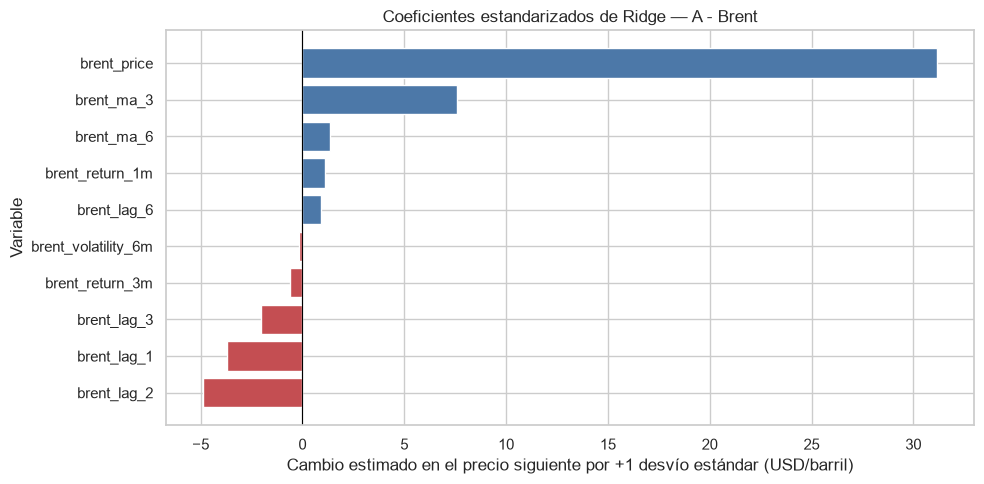

In [17]:
ridge_pipeline = selected_regression_models[best_reg_scenario]
assert isinstance(ridge_pipeline.named_steps["model"], Ridge)
ridge_scaler = ridge_pipeline.named_steps["scaler"]
ridge_model = ridge_pipeline.named_steps["model"]
ridge_coefficients = pd.DataFrame({
    "variable": best_reg_features,
    "coeficiente_USD_por_1DE": ridge_model.coef_,
    "desvio_original": ridge_scaler.scale_,
})
ridge_coefficients["magnitud_absoluta"] = ridge_coefficients["coeficiente_USD_por_1DE"].abs()
display(ridge_coefficients.sort_values("magnitud_absoluta", ascending=False).round(3))
print(f"Intercepto del modelo: USD {ridge_model.intercept_:.3f}")

ridge_plot = ridge_coefficients.sort_values("coeficiente_USD_por_1DE")
colors = np.where(ridge_plot["coeficiente_USD_por_1DE"] >= 0, "#4c78a8", "#c44e52")
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(ridge_plot["variable"], ridge_plot["coeficiente_USD_por_1DE"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(
    title=f"Coeficientes estandarizados de Ridge — {best_reg_scenario}",
    xlabel="Cambio estimado en el precio siguiente por +1 desvío estándar (USD/barril)",
    ylabel="Variable",
)
plt.tight_layout()
plt.show()

El precio actual concentra el coeficiente positivo más grande: +USD 31,18 por un desvío estándar, seguido por la media móvil de tres meses (+USD 7,57). Los rezagos de uno y dos meses tienen coeficientes negativos (−USD 3,72 y −USD 4,88), que compensan el nivel actual y las medias móviles dentro de una estructura muy correlacionada. Retornos y volatilidad tienen magnitudes menores. Los signos describen la combinación usada por Ridge, no efectos causales ni el resultado de modificar una variable de manera aislada.

## 13. SHAP para el Random Forest del escenario C (diagnóstico, no selección)

Se explica el Random Forest **de regresión** optimizado de C para incluir historia del Brent, GPR y mercado mundial en el mismo análisis. `TreeExplainer` opera sobre las 66 observaciones del test, una muestra pequeña y suficiente; sus aportes están en la salida cruda del modelo, es decir, USD/barril. Al no explicar aquí un clasificador binario, no existe ambigüedad sobre la clase positiva.

Control de aditividad SHAP: correcto
Forma de los valores SHAP: (66, 18) | salida: USD por barril


,media_abs_SHAP_USD,aumento_RMSE_permutacion
brent_price,18.836,17.164
world_market_balance_lag_1,0.463,0.024
brent_return_1m,0.397,0.098
brent_return_3m,0.372,0.024
brent_ma_3,0.220,-0.002
brent_lag_1,0.218,0.031
brent_lag_3,0.212,0.062
brent_ma_6,0.162,0.024
world_production_lag_1,0.151,0.002
gpr_lag_1,0.101,-0.005


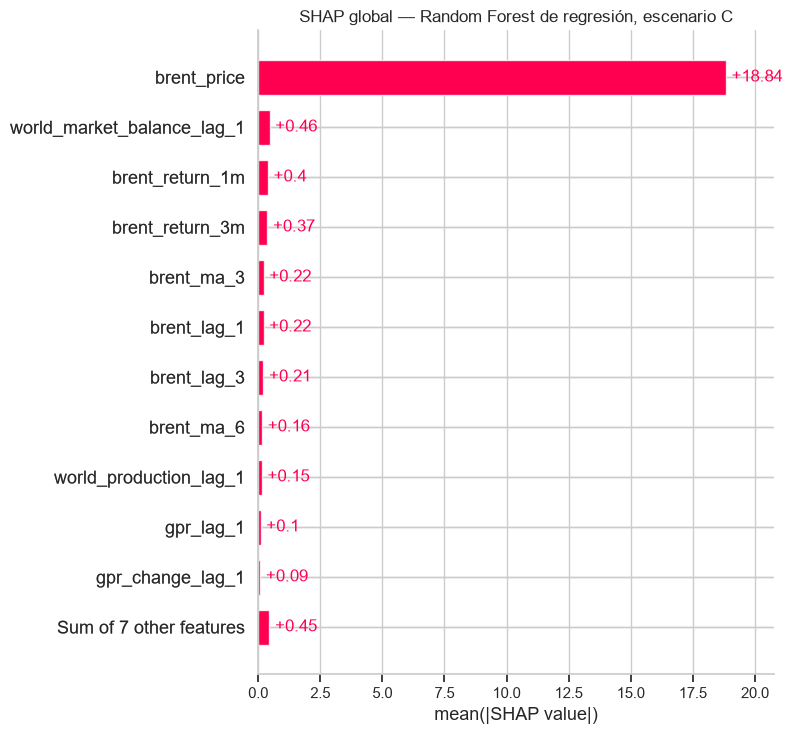

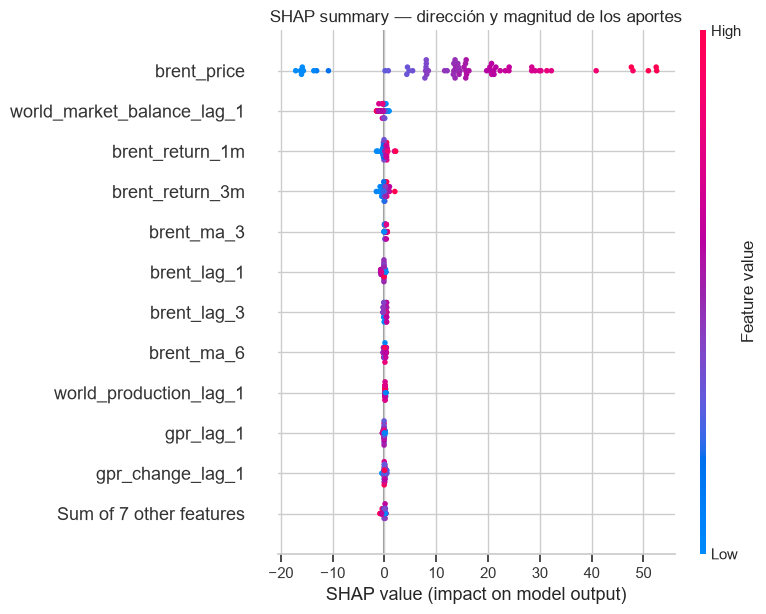

Caso local: 2022-02 | real: USD 117.25 | predicción RF C: USD 91.82 | error: USD +25.43


,aporte_SHAP_USD
brent_price,31.358
world_market_balance_lag_1,-1.413
brent_return_1m,0.656
brent_return_3m,0.654
gpr_lag_1,-0.384
brent_ma_3,0.373
world_market_balance_change_lag_1,-0.209
brent_volatility_6m,-0.192


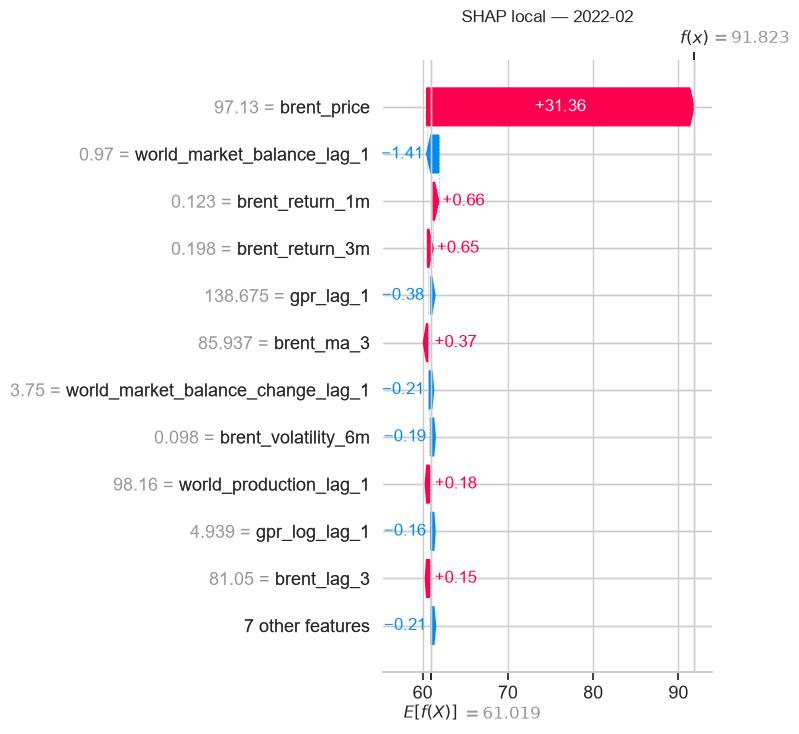

In [18]:
scenario_c_name = "C - Brent + GPR + mercado"
rf_c_pipeline = regression_searches[scenario_c_name].best_estimator_
rf_c_model = rf_c_pipeline.named_steps["model"]
X_shap = test[features_c].copy()
rf_c_predictions = rf_c_pipeline.predict(X_shap)

shap_explainer = shap.TreeExplainer(rf_c_model)
shap_values_c = shap_explainer(X_shap)
assert shap_values_c.values.shape == X_shap.shape
shap_reconstructed = np.asarray(shap_values_c.base_values).reshape(-1) + shap_values_c.values.sum(axis=1)
assert np.allclose(shap_reconstructed, rf_c_predictions, atol=1e-6)
print("Control de aditividad SHAP: correcto")
print("Forma de los valores SHAP:", shap_values_c.values.shape, "| salida: USD por barril")

shap_global = pd.Series(
    np.abs(shap_values_c.values).mean(axis=0), index=features_c, name="media_abs_SHAP_USD"
)
rf_c_permutation = permutation_importance(
    rf_c_pipeline, X_shap, y_reg_test, scoring="neg_root_mean_squared_error",
    n_repeats=20, random_state=RANDOM_STATE, n_jobs=1,
)
shap_vs_permutation = pd.DataFrame({
    "media_abs_SHAP_USD": shap_global,
    "aumento_RMSE_permutacion": rf_c_permutation.importances_mean,
}).sort_values("media_abs_SHAP_USD", ascending=False)
display(shap_vs_permutation.head(10).round(3))

shap.plots.bar(shap_values_c, max_display=12, show=False)
plt.title("SHAP global — Random Forest de regresión, escenario C")
plt.tight_layout()
plt.show()

shap.plots.beeswarm(shap_values_c, max_display=12, show=False)
plt.title("SHAP summary — dirección y magnitud de los aportes")
plt.tight_layout()
plt.show()

local_position = int(np.argmax(np.abs(y_reg_test.to_numpy() - rf_c_predictions)))
local_month = test.iloc[local_position]["month"]
local_actual = float(y_reg_test.iloc[local_position])
local_prediction = float(rf_c_predictions[local_position])
local_shap = shap_values_c[local_position]
assert np.isclose(float(local_shap.base_values) + local_shap.values.sum(), local_prediction, atol=1e-6)
print(
    f"Caso local: {local_month:%Y-%m} | real: USD {local_actual:.2f} | "
    f"predicción RF C: USD {local_prediction:.2f} | error: USD {local_actual - local_prediction:+.2f}"
)
shap_local_table = pd.Series(local_shap.values, index=features_c, name="aporte_SHAP_USD")
shap_local_table = shap_local_table.reindex(shap_local_table.abs().sort_values(ascending=False).index)
display(shap_local_table.head(8).to_frame().round(3))
shap.plots.waterfall(local_shap, max_display=12, show=False)
plt.title(f"SHAP local — {local_month:%Y-%m}")
plt.tight_layout()
plt.show()

La importancia global SHAP está dominada por `brent_price` (media absoluta: USD 18,84). Muy lejos aparecen el balance mundial rezagado (USD 0,46), los retornos de uno y tres meses (USD 0,40 y 0,37), la producción mundial (USD 0,15) y GPR rezagado (USD 0,10). El beeswarm confirma que precios actuales altos empujan la predicción hacia arriba; para las variables externas los aportes son pequeños y sin una separación tan clara. Permutación coincide en el dominio del precio actual, aunque cambia el orden secundario porque romper una columna y repartir contribuciones entre variables correlacionadas responden preguntas diferentes.

En febrero de 2022, un Brent actual de USD 97,13 aporta +USD 31,36 sobre la referencia SHAP de USD 61,02. El balance rezagado resta USD 1,41 y GPR resta USD 0,38; el bosque predice USD 91,82 frente a los USD 117,25 observados al mes siguiente, un error de USD 25,43. La explicación revela cómo decidió el modelo y, simultáneamente, su incapacidad para anticipar por completo ese salto. Dado que su RMSE sigue por encima de la persistencia, estos aportes no prueban utilidad predictiva robusta ni causalidad.

## 14. LIME: contraste local con SHAP

LIME aproxima el Random Forest alrededor de la misma observación explicada por SHAP mediante perturbaciones y un modelo lineal local. Se genera una sola explicación para evitar redundancia y se fija la semilla para hacerla reproducible.

,condición local,peso LIME
0,brent_price > 78.34,56.876
1,world_market_balance_lag_1 > 0.48,-1.192
2,brent_ma_6 > 77.75,1.165
3,57.52 < brent_lag_6 <= 78.34,1.136
4,brent_lag_3 > 78.34,1.085
5,gpr_lag_1 > 110.88,-0.764
6,brent_return_3m > 0.14,0.757
7,gpr_change_lag_1 > 9.74,0.603


Predicción del bosque: USD 91.82 | aproximación lineal local de LIME: USD 106.00


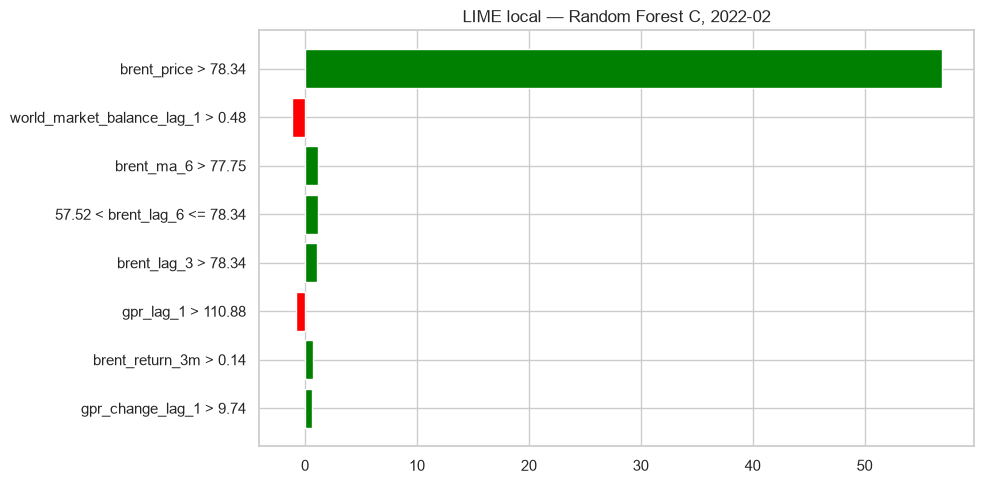

In [19]:
lime_explainer = LimeTabularExplainer(
    train[features_c].to_numpy(),
    feature_names=features_c,
    mode="regression",
    discretize_continuous=True,
    random_state=RANDOM_STATE,
)
lime_explanation = lime_explainer.explain_instance(
    X_shap.iloc[local_position].to_numpy(),
    rf_c_model.predict,
    num_features=8,
    num_samples=3000,
)
lime_table = pd.DataFrame(lime_explanation.as_list(), columns=["condición local", "peso LIME"])
display(lime_table.round(3))
print(
    f"Predicción del bosque: USD {local_prediction:.2f} | "
    f"aproximación lineal local de LIME: USD {float(lime_explanation.local_pred[0]):.2f}"
)
fig = lime_explanation.as_pyplot_figure()
fig.set_size_inches(10, 5)
plt.title(f"LIME local — Random Forest C, {local_month:%Y-%m}")
plt.tight_layout()
plt.show()

SHAP y LIME coinciden en que el nivel actual del Brent domina el caso de febrero de 2022 y asignan papeles secundarios al balance y al GPR. Sin embargo, el sustituto de LIME aproxima USD 106,00 frente a la predicción real del bosque de USD 91,82: una diferencia de USD 14,18 que indica fidelidad local limitada. SHAP conserva la aditividad exacta del modelo de árboles; LIME ofrece reglas por intervalos intuitivas, pero depende de perturbaciones y de una aproximación lineal. Por eso se conserva como contraste didáctico y no como confirmación independiente ni evidencia causal.

## 15. Conclusiones

1. **Selección metodológica.** Ridge A es el mejor modelo aprendido de regresión por RMSE de validación temporal (7,347), pero la persistencia es mejor (6,017). En clasificación, el Random Forest optimizado de B se selecciona por balanced accuracy CV (0,532); no se elige C por su resultado de test.
2. **Evaluación histórica.** En el test ya inspeccionado, Ridge A obtiene MAE 5,014, RMSE 6,238 y R² 0,864; la persistencia logra MAE 4,942 y RMSE 6,243. La diferencia de RMSE es mínima y cambia de signo en MAE, por lo que no existe una superioridad robusta del modelo aprendido. R² mide mejora frente a la media, no porcentaje de aciertos.
3. **Clasificación.** El clasificador B congelado por CV obtiene en el test histórico balanced accuracy 0,456, por debajo del 0,500 mayoritario. Su rendimiento cambia entre validación y test, lo que evidencia baja estabilidad temporal; accuracy, F1 y ROC-AUC se interpretan junto con la matriz de confusión y no de forma aislada.
4. **Riesgo geopolítico y mercado mundial.** Agregar GPR no mejora Ridge frente a A. El mismo Random Forest reduce algo su RMSE en B, pero sigue por encima de persistencia; C tampoco aporta una mejora consistente. Las diferencias pequeñas entre escenarios no justifican afirmar una ganancia predictiva estable.
5. **Overfitting.** Random Forest y Gradient Boosting presentan brechas de RMSE superiores a 10 entre entrenamiento y validación; los bosques de clasificación también muestran brechas amplias de balanced accuracy. La optimización compacta no elimina esa inestabilidad.
6. **Interpretabilidad.** Ridge A depende sobre todo del nivel actual y de medias/rezagos. SHAP para el Random Forest C coloca `brent_price` muy por encima del resto; balance, producción y GPR son secundarios. Ese bosque C se conserva como diagnóstico para estudiar variables externas, no como modelo final seleccionado.
7. **SHAP y LIME.** SHAP reconstruye exactamente la salida del bosque y muestra cómo subestimó el salto posterior a febrero de 2022. LIME coincide en variables dominantes, pero su aproximación local tiene fidelidad limitada. Ambas técnicas explican el comportamiento del modelo; no prueban capacidad predictiva, causalidad ni utilidad de una variable por sí sola.
8. **Limitaciones.** El test mensual fue observado durante el desarrollo y solo vale como referencia histórica exploratoria. Además, STEO contiene historia revisada, los retrasos de publicación se aproximan, la muestra es pequeña y faltan variables de inventarios, macroeconomía y decisiones de oferta.

El resultado central es negativo pero informativo: bajo una selección basada exclusivamente en validación temporal, no aparece evidencia estable de que GPR u oferta/demanda mejoren la predicción mensual del Brent respecto de su propia persistencia.


In [20]:
best_reg = regression_test.query("escenario == @best_reg_scenario").iloc[0]
best_clf = classification_test.query("escenario == @best_clf_scenario").iloc[0]

summary = {
    "periodo_modelado": [model_data["month"].min().strftime("%Y-%m"), model_data["month"].max().strftime("%Y-%m")],
    "periodo_test_historico": [test["month"].min().strftime("%Y-%m"), test["month"].max().strftime("%Y-%m")],
    "advertencia_test": "Test ya inspeccionado; evaluación histórica exploratoria, no holdout completamente independiente.",
    "baseline_regression_rmse_cv": float(baseline_reg_cv["RMSE"].mean()),
    "selected_regression_scenario_by_cv": best_reg_scenario,
    "selected_regression_model_by_cv": best_reg_model_name,
    "selected_regression_rmse_cv": float(final_reg_config["RMSE_CV"]),
    "historical_test_regression_mae": float(best_reg["MAE_test"]),
    "historical_test_regression_rmse": float(best_reg["RMSE_test"]),
    "historical_test_regression_r2": float(best_reg["R2_test"]),
    "baseline_classification_balanced_accuracy_cv": float(baseline_clf_cv["Balanced_accuracy"].mean()),
    "selected_classification_scenario_by_cv": best_clf_scenario,
    "selected_classification_model_by_cv": best_clf_model_name,
    "selected_classification_balanced_accuracy_cv": float(final_clf_config["Balanced_accuracy_CV"]),
    "historical_test_classification_accuracy": float(best_clf["Accuracy_test"]),
    "historical_test_classification_balanced_accuracy": float(best_clf["Balanced_accuracy_test"]),
    "historical_test_classification_f1_positive": float(best_clf["F1_positivo_test"]),
    "historical_test_classification_f1_macro": float(best_clf["F1_macro_test"]),
    "historical_test_classification_roc_auc": float(best_clf["ROC_AUC_test"]),
    "same_algorithm_regression": same_algorithm_reg.to_dict(orient="records"),
    "same_algorithm_classification": same_algorithm_clf.to_dict(orient="records"),
}

print("RESULTADOS_RESUMEN")
print(json.dumps(summary, ensure_ascii=False, indent=2))


RESULTADOS_RESUMEN
{
  "periodo_modelado": [
    "1998-07",
    "2025-11"
  ],
  "periodo_test_historico": [
    "2020-06",
    "2025-11"
  ],
  "advertencia_test": "Test ya inspeccionado; evaluación histórica exploratoria, no holdout completamente independiente.",
  "baseline_regression_rmse_cv": 6.016520616724373,
  "selected_regression_scenario_by_cv": "A - Brent",
  "selected_regression_model_by_cv": "Ridge",
  "selected_regression_rmse_cv": 7.346737089296212,
  "historical_test_regression_mae": 5.014257271157401,
  "historical_test_regression_rmse": 6.237516091977696,
  "historical_test_regression_r2": 0.863715930395177,
  "baseline_classification_balanced_accuracy_cv": 0.5,
  "selected_classification_scenario_by_cv": "B - Brent + GPR",
  "selected_classification_model_by_cv": "Random Forest optimizado",
  "selected_classification_balanced_accuracy_cv": 0.5318965178044462,
  "historical_test_classification_accuracy": 0.45454545454545453,
  "historical_test_classification_balanced_